In [1]:
import os
import tensorflow as tf

print("Python:", os.sys.executable)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


I0000 00:00:1790434590.702773   39376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790434590.894317   39376 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790434594.633645   39376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: /home/allen/deepfake-gpu/bin/python
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

print("Project folder:")
print(PROJECT_DIR)

print("\nFiles/folders:")
for item in PROJECT_DIR.iterdir():
    print(item.name)

Project folder:
/mnt/c/vs code/deep fake image detection

Files/folders:
.dist
DeepFake_Detection.ipynb


In [4]:
from pathlib import Path

possible_paths = [
    Path("/mnt/c/Users") / "Public",
    Path("/mnt/c/Users") / "allen",
    Path("/mnt/c/Users") / "Downloads",
    Path("/mnt/c/Users") / "Desktop",
]

for path in possible_paths:
    if path.exists():
        print(f"✓ {path}")

✓ /mnt/c/Users/Public
✓ /mnt/c/Users/allen


In [5]:
from pathlib import Path

downloads = Path("/mnt/c/Users/allen/Downloads")

print("Downloads exists:", downloads.exists())

if downloads.exists():
    for item in downloads.iterdir():
        print(item.name)

Downloads exists: True
archive.zip
certificates
DEEP LEARING PROJECT
desktop.ini
dfiles .dont delete this file
NOTES
Telegram Desktop
Untitled design.pdf
WORKS


In [6]:
from pathlib import Path

zip_file = Path("/mnt/c/Users/allen/Downloads/archive.zip")

print("Exists:", zip_file.exists())
print("Size:", f"{zip_file.stat().st_size / (1024**3):.2f} GB")

Exists: True
Size: 1.68 GB


In [7]:
import zipfile

zip_file = "/mnt/c/Users/allen/Downloads/archive.zip"

with zipfile.ZipFile(zip_file, "r") as z:
    names = z.namelist()
    print("Total files in ZIP:", len(names))
    print("\nFirst 20 entries:")
    for name in names[:20]:
        print(name)

Total files in ZIP: 190335

First 20 entries:
Dataset/Test/Fake/fake_0.jpg
Dataset/Test/Fake/fake_1.jpg
Dataset/Test/Fake/fake_10.jpg
Dataset/Test/Fake/fake_100.jpg
Dataset/Test/Fake/fake_1000.jpg
Dataset/Test/Fake/fake_1001.jpg
Dataset/Test/Fake/fake_1002.jpg
Dataset/Test/Fake/fake_1003.jpg
Dataset/Test/Fake/fake_1004.jpg
Dataset/Test/Fake/fake_1005.jpg
Dataset/Test/Fake/fake_1006.jpg
Dataset/Test/Fake/fake_1007.jpg
Dataset/Test/Fake/fake_1008.jpg
Dataset/Test/Fake/fake_1009.jpg
Dataset/Test/Fake/fake_101.jpg
Dataset/Test/Fake/fake_1010.jpg
Dataset/Test/Fake/fake_1011.jpg
Dataset/Test/Fake/fake_1012.jpg
Dataset/Test/Fake/fake_1013.jpg
Dataset/Test/Fake/fake_1014.jpg


In [8]:
import shutil

total, used, free = shutil.disk_usage("/home")

print("Total storage :", f"{total / (1024**3):.2f} GB")
print("Used storage  :", f"{used / (1024**3):.2f} GB")
print("Free storage  :", f"{free / (1024**3):.2f} GB")

Total storage : 1006.85 GB
Used storage  : 19.40 GB
Free storage  : 936.23 GB


In [9]:
from pathlib import Path
import zipfile
import time

zip_file = Path("/mnt/c/Users/allen/Downloads/archive.zip")
extract_dir = Path("/home/allen/deepfake-data")

extract_dir.mkdir(parents=True, exist_ok=True)

print("Extracting dataset...")
start = time.time()

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(extract_dir)

elapsed = (time.time() - start) / 60

print(f"\nExtraction completed in {elapsed:.1f} minutes.")
print("Dataset location:", extract_dir)

Extracting dataset...

Extraction completed in 5.2 minutes.
Dataset location: /home/allen/deepfake-data


In [10]:
from pathlib import Path

DATASET_DIR = Path("/home/allen/deepfake-data/Dataset")

for split in ["Train", "Validation", "Test"]:
    print(f"\n{split}:")
    
    for class_name in ["Fake", "Real"]:
        folder = DATASET_DIR / split / class_name
        count = len(list(folder.glob("*.jpg")))
        print(f"  {class_name}: {count:,} images")


Train:
  Fake: 70,001 images
  Real: 70,001 images

Validation:
  Fake: 19,641 images
  Real: 19,787 images

Test:
  Fake: 5,492 images
  Real: 5,413 images


In [11]:
from pathlib import Path

DATASET_DIR = Path("/home/allen/deepfake-data/Dataset")

TRAIN_DIR = DATASET_DIR / "Train"
VAL_DIR   = DATASET_DIR / "Validation"
TEST_DIR  = DATASET_DIR / "Test"

print("Train   :", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test    :", TEST_DIR)

Train   : /home/allen/deepfake-data/Dataset/Train
Validation: /home/allen/deepfake-data/Dataset/Validation
Test    : /home/allen/deepfake-data/Dataset/Test


In [12]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 16

train_data = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_data = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_data = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("\nClass names:", train_data.class_names)

Found 140002 files belonging to 2 classes.


I0000 00:00:1790435771.238697   39376 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1766 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 39428 files belonging to 2 classes.
Found 10905 files belonging to 2 classes.

Class names: ['Fake', 'Real']


In [13]:
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(AUTOTUNE)
val_data = val_data.prefetch(AUTOTUNE)
test_data = test_data.prefetch(AUTOTUNE)

print("Data pipeline ready.")

Data pipeline ready.


In [14]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])

print("Data augmentation ready.")

Data augmentation ready.


In [15]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded.")
print("Total layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EfficientNetB0 loaded.
Total layers: 238


In [16]:
from tensorflow.keras import layers, models

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from pathlib import Path

MODEL_DIR = Path("/mnt/c/vs code/deep fake image detection/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_frozen_model.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("Training callbacks ready.")
print("Models will be saved in:", MODEL_DIR)

Training callbacks ready.
Models will be saved in: /mnt/c/vs code/deep fake image detection/models


In [19]:
EPOCHS_INITIAL = 5

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS_INITIAL,
    callbacks=callbacks
)

Epoch 1/5


/home/allen/deepfake-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1790436472.518595   46756 cuda_dnn.cc:461] Loaded cuDNN version 92600


8751/8751 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.7444 - loss: 0.5090 - precision: 0.7331 - recall: 0.7686
Epoch 1: val_accuracy improved from None to 0.76496, saving model to /mnt/c/vs code/deep fake image detection/models/best_frozen_model.keras

Epoch 1: finished saving model to /mnt/c/vs code/deep fake image detection/models/best_frozen_model.keras
8751/8751 ━━━━━━━━━━━━━━━━━━━━ 1284s 145ms/step - accuracy: 0.7444 - loss: 0.5090 - precision: 0.7331 - recall: 0.7686 - val_accuracy: 0.7650 - val_loss: 0.4789 - val_precision: 0.9000 - val_recall: 0.5981 - learning_rate: 1.0000e-04
Epoch 2/5
8750/8751 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.7653 - loss: 0.4782 - precision: 0.7517 - recall: 0.7924
Epoch 2: val_accuracy improved from 0.76496 to 0.77161, saving model to /mnt/c/vs code/deep fake image detection/models/best_frozen_model.keras

Epoch 2: finished saving model to /mnt/c/vs code/deep fake image detection/models/best_frozen_model.keras
8751/8751 ━━━━━━━━━━━━━━━━

In [21]:
print("Best validation accuracy:",
      f"{max(history.history['val_accuracy']) * 100:.2f}%")

print("Best validation loss:",
      f"{min(history.history['val_loss']):.4f}")

print("\nFinal training accuracy:",
      f"{history.history['accuracy'][-1] * 100:.2f}%")

print("Final validation accuracy:",
      f"{history.history['val_accuracy'][-1] * 100:.2f}%")

Best validation accuracy: 77.57%
Best validation loss: 0.4621

Final training accuracy: 77.89%
Final validation accuracy: 77.32%


In [22]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total EfficientNet layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Total EfficientNet layers: 238
Trainable layers: 30


In [23]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model recompiled for fine-tuning.")
print("Learning rate: 0.00001")

Model recompiled for fine-tuning.
Learning rate: 0.00001


In [24]:
fine_tune_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_finetuned_model.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("Fine-tuning callbacks ready.")

Fine-tuning callbacks ready.


In [25]:
EPOCHS_FINE_TUNE = 5

fine_tune_history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=fine_tune_callbacks
)

Epoch 1/5


E0000 00:00:1790444498.173651   39376 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


8751/8751 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8222 - loss: 0.3861 - precision: 0.8172 - recall: 0.8301
Epoch 1: val_accuracy improved from None to 0.85772, saving model to /mnt/c/vs code/deep fake image detection/models/best_finetuned_model.keras

Epoch 1: finished saving model to /mnt/c/vs code/deep fake image detection/models/best_finetuned_model.keras
8751/8751 ━━━━━━━━━━━━━━━━━━━━ 1000s 112ms/step - accuracy: 0.8222 - loss: 0.3861 - precision: 0.8172 - recall: 0.8301 - val_accuracy: 0.8577 - val_loss: 0.3315 - val_precision: 0.9354 - val_recall: 0.7696 - learning_rate: 1.0000e-05
Epoch 2/5
8751/8751 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8801 - loss: 0.2771 - precision: 0.8759 - recall: 0.8857
Epoch 2: val_accuracy improved from 0.85772 to 0.88077, saving model to /mnt/c/vs code/deep fake image detection/models/best_finetuned_model.keras

Epoch 2: finished saving model to /mnt/c/vs code/deep fake image detection/models/best_finetuned_model.keras
8751/8751 ━━━━━

In [26]:
print("Best fine-tuning validation accuracy:",
      f"{max(fine_tune_history.history['val_accuracy']) * 100:.2f}%")

print("Best fine-tuning validation loss:",
      f"{min(fine_tune_history.history['val_loss']):.4f}")

print("\nFinal training accuracy:",
      f"{fine_tune_history.history['accuracy'][-1] * 100:.2f}%")

print("Final validation accuracy:",
      f"{fine_tune_history.history['val_accuracy'][-1] * 100:.2f}%")

Best fine-tuning validation accuracy: 90.55%
Best fine-tuning validation loss: 0.2373

Final training accuracy: 91.78%
Final validation accuracy: 90.55%


In [27]:
test_results = model.evaluate(
    test_data,
    verbose=1
)

print("\nTest Results:")
for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

682/682 ━━━━━━━━━━━━━━━━━━━━ 42s 60ms/step - accuracy: 0.7920 - loss: 0.5510 - precision: 0.9263 - recall: 0.6313

Test Results:
loss: 0.5510
compile_metrics: 0.7920


In [30]:
!pip install -q scikit-learn

In [31]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_prob = []

for images, labels in test_data:
    probabilities = model.predict(images, verbose=0).ravel()
    y_prob.extend(probabilities)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

# Default threshold
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Fake", "Real"],
        digits=4
    )
)

Confusion Matrix:
[[5220  272]
 [1996 3417]]

Classification Report:
              precision    recall  f1-score   support

        Fake     0.7234    0.9505    0.8215      5492
        Real     0.9263    0.6313    0.7508      5413

    accuracy                         0.7920     10905
   macro avg     0.8248    0.7909    0.7862     10905
weighted avg     0.8241    0.7920    0.7864     10905



In [32]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Get validation probabilities
val_true = []
val_prob = []

for images, labels in val_data:
    probabilities = model.predict(images, verbose=0).ravel()
    val_prob.extend(probabilities)
    val_true.extend(labels.numpy().ravel())

val_true = np.array(val_true).astype(int)
val_prob = np.array(val_prob)

# Test several thresholds using VALIDATION data only
thresholds = np.arange(0.10, 0.91, 0.05)

print("Validation threshold results:\n")

best_threshold = 0
best_f1 = 0

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    acc = accuracy_score(val_true, val_pred)
    precision = precision_score(val_true, val_pred)
    recall = recall_score(val_true, val_pred)
    f1 = f1_score(val_true, val_pred)

    print(
        f"Threshold {threshold:.2f} | "
        f"Accuracy: {acc:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("\nBest validation threshold:", best_threshold)
print("Best validation F1:", f"{best_f1:.4f}")

Validation threshold results:

Threshold 0.10 | Accuracy: 0.9117 | Precision: 0.8780 | Recall: 0.9570 | F1: 0.9158
Threshold 0.15 | Accuracy: 0.9168 | Precision: 0.8969 | Recall: 0.9426 | F1: 0.9192
Threshold 0.20 | Accuracy: 0.9198 | Precision: 0.9116 | Recall: 0.9305 | F1: 0.9209
Threshold 0.25 | Accuracy: 0.9203 | Precision: 0.9227 | Recall: 0.9182 | F1: 0.9204
Threshold 0.30 | Accuracy: 0.9192 | Precision: 0.9314 | Recall: 0.9057 | F1: 0.9184
Threshold 0.35 | Accuracy: 0.9171 | Precision: 0.9379 | Recall: 0.8941 | F1: 0.9154
Threshold 0.40 | Accuracy: 0.9132 | Precision: 0.9437 | Recall: 0.8796 | F1: 0.9105
Threshold 0.45 | Accuracy: 0.9093 | Precision: 0.9488 | Recall: 0.8660 | F1: 0.9055
Threshold 0.50 | Accuracy: 0.9055 | Precision: 0.9550 | Recall: 0.8520 | F1: 0.9005
Threshold 0.55 | Accuracy: 0.9000 | Precision: 0.9597 | Recall: 0.8358 | F1: 0.8935
Threshold 0.60 | Accuracy: 0.8949 | Precision: 0.9649 | Recall: 0.8204 | F1: 0.8868
Threshold 0.65 | Accuracy: 0.8872 | Precision

In [33]:
BEST_THRESHOLD = 0.20

test_pred = (y_prob >= BEST_THRESHOLD).astype(int)

test_accuracy = accuracy_score(y_true, test_pred)
test_precision = precision_score(y_true, test_pred)
test_recall = recall_score(y_true, test_pred)
test_f1 = f1_score(y_true, test_pred)

print("FINAL TEST RESULTS")
print("------------------")
print(f"Threshold : {BEST_THRESHOLD:.2f}")
print(f"Accuracy  : {test_accuracy * 100:.2f}%")
print(f"Precision : {test_precision * 100:.2f}%")
print(f"Recall    : {test_recall * 100:.2f}%")
print(f"F1 Score  : {test_f1 * 100:.2f}%")

FINAL TEST RESULTS
------------------
Threshold : 0.20
Accuracy  : 83.36%
Precision : 87.59%
Recall    : 77.44%
F1 Score  : 82.20%


In [34]:
from pathlib import Path

MODEL_DIR = Path("/mnt/c/vs code/deep fake image detection/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = MODEL_DIR / "deepfake_detector_final.keras"

model.save(FINAL_MODEL_PATH)

with open(MODEL_DIR / "threshold.txt", "w") as f:
    f.write(str(BEST_THRESHOLD))

print("Final model saved:")
print(FINAL_MODEL_PATH)

print("\nThreshold saved:")
print(MODEL_DIR / "threshold.txt")

Final model saved:
/mnt/c/vs code/deep fake image detection/models/deepfake_detector_final.keras

Threshold saved:
/mnt/c/vs code/deep fake image detection/models/threshold.txt


In [35]:
from sklearn.metrics import confusion_matrix

final_cm = confusion_matrix(y_true, test_pred)

print("Final Confusion Matrix (Threshold = 0.20)")
print(final_cm)

print("\nTN:", final_cm[0, 0])
print("FP:", final_cm[0, 1])
print("FN:", final_cm[1, 0])
print("TP:", final_cm[1, 1])

Final Confusion Matrix (Threshold = 0.20)
[[4898  594]
 [1221 4192]]

TN: 4898
FP: 594
FN: 1221
TP: 4192


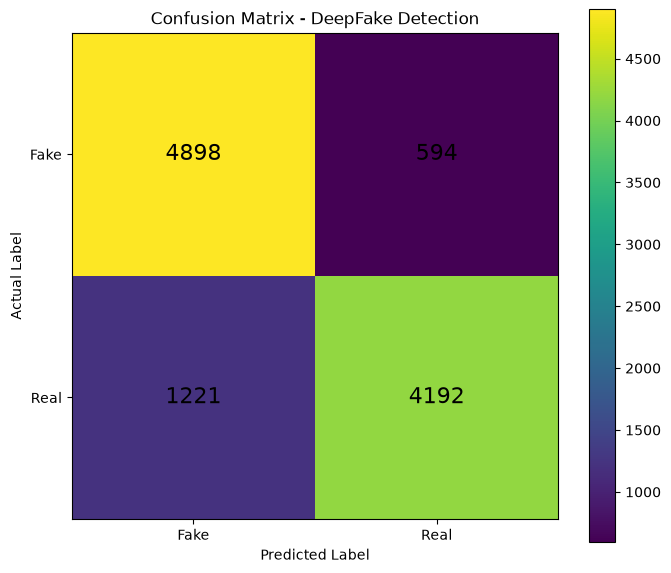

In [38]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 6))

plt.imshow(final_cm)

plt.title("Confusion Matrix - DeepFake Detection")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Fake", "Real"])
plt.yticks([0, 1], ["Fake", "Real"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            str(final_cm[i, j]),
            ha="center",
            va="center",
            fontsize=16
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [37]:
!pip install -q matplotlib

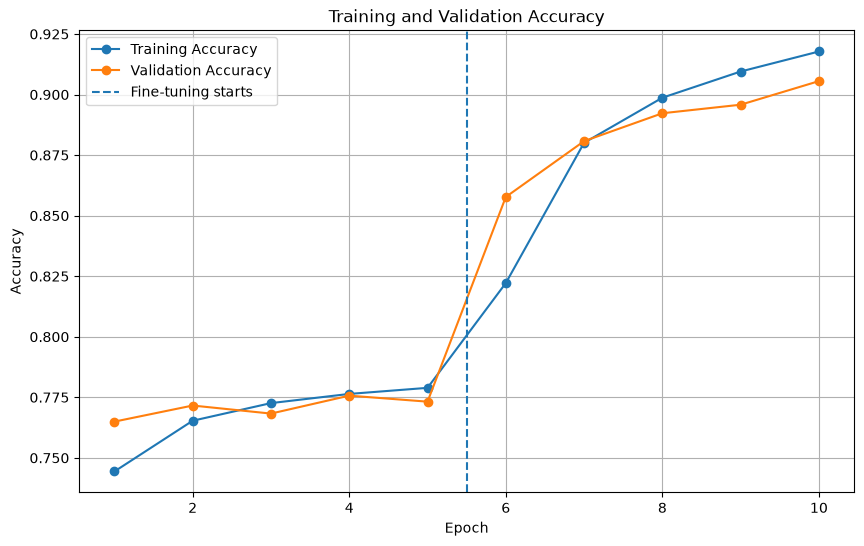

In [39]:
train_acc = history.history["accuracy"] + fine_tune_history.history["accuracy"]
val_acc = history.history["val_accuracy"] + fine_tune_history.history["val_accuracy"]

train_loss = history.history["loss"] + fine_tune_history.history["loss"]
val_loss = history.history["val_loss"] + fine_tune_history.history["val_loss"]

epochs = range(1, len(train_acc) + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs, train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs, val_acc, marker="o", label="Validation Accuracy")

plt.axvline(
    x=len(history.history["accuracy"]) + 0.5,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

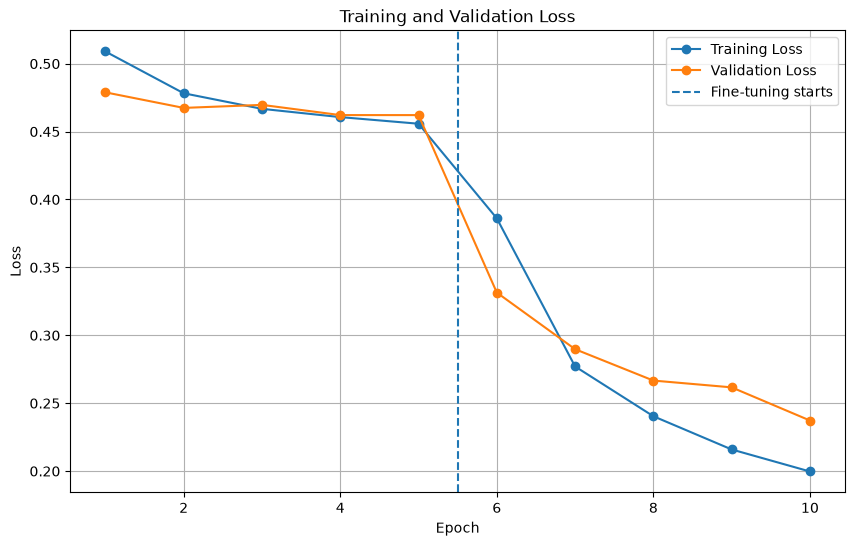

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.axvline(
    x=len(history.history["loss"]) + 0.5,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [42]:
BEST_THRESHOLD = 0.20

def predict_deepfake(image_path):
    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    probability_real = float(
        model.predict(img_array, verbose=0)[0][0]
    )

    if probability_real >= BEST_THRESHOLD:
        prediction = "REAL"
        confidence = probability_real * 100
    else:
        prediction = "FAKE"
        confidence = (1 - probability_real) * 100

    print("Prediction :", prediction)
    print("Confidence :", f"{confidence:.2f}%")
    print("Probability of Real :", f"{probability_real:.4f}")
    print("Probability of Fake :", f"{1 - probability_real:.4f}")

    return prediction, confidence

In [43]:
print("Prediction function is ready.")
print("Threshold:", BEST_THRESHOLD)

Prediction function is ready.
Threshold: 0.2


In [45]:
!pip install -q Pillow

In [50]:
import sys

print("Python used by notebook:")
print(sys.executable)

try:
    import PIL
    print("\nPillow is installed.")
    print("Pillow version:", PIL.__version__)
except Exception as e:
    print("\nPillow is NOT available.")
    print("Error:", e)

Python used by notebook:
/home/allen/deepfake-gpu/bin/python

Pillow is installed.
Pillow version: 12.3.0


In [51]:
def predict_deepfake(image_path):
    # Read image directly with TensorFlow
    image_bytes = tf.io.read_file(str(image_path))
    img = tf.image.decode_jpeg(image_bytes, channels=3)
    img = tf.image.resize(img, (224, 224))

    # Add batch dimension
    img_array = tf.expand_dims(img, axis=0)

    # Predict
    probability_real = float(
        model.predict(img_array, verbose=0)[0][0]
    )

    if probability_real >= BEST_THRESHOLD:
        prediction = "REAL"
        confidence = probability_real * 100
    else:
        prediction = "FAKE"
        confidence = (1 - probability_real) * 100

    print("Prediction :", prediction)
    print("Confidence :", f"{confidence:.2f}%")
    print("Probability of Real :", f"{probability_real:.4f}")
    print("Probability of Fake :", f"{1 - probability_real:.4f}")

    return prediction, confidence

print("Prediction function updated successfully.")

Prediction function updated successfully.


In [52]:
fake_image = TEST_DIR / "Fake" / "fake_768.jpg"

print("Testing image:", fake_image)

prediction, confidence = predict_deepfake(fake_image)

Testing image: /home/allen/deepfake-data/Dataset/Test/Fake/fake_768.jpg
Prediction : FAKE
Confidence : 99.93%
Probability of Real : 0.0007
Probability of Fake : 0.9993


In [53]:
real_image = TEST_DIR / "Real" / "real_952.jpg"

print("Testing image:", real_image)

prediction, confidence = predict_deepfake(real_image)

Testing image: /home/allen/deepfake-data/Dataset/Test/Real/real_952.jpg
Prediction : REAL
Confidence : 32.30%
Probability of Real : 0.3230
Probability of Fake : 0.6770


In [54]:
!pip install -q gradio

In [55]:
import gradio as gr
import tensorflow as tf
import numpy as np
from pathlib import Path

# ============================================================
# LOAD SAVED MODEL
# ============================================================

MODEL_PATH = Path(
    "/mnt/c/vs code/deep fake image detection/models/deepfake_detector_final.keras"
)

THRESHOLD_PATH = Path(
    "/mnt/c/vs code/deep fake image detection/models/threshold.txt"
)

detector_model = tf.keras.models.load_model(MODEL_PATH)

with open(THRESHOLD_PATH, "r") as f:
    DETECTION_THRESHOLD = float(f.read().strip())

print("Model loaded successfully.")
print("Detection threshold:", DETECTION_THRESHOLD)


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def detect_deepfake(image):
    if image is None:
        return (
            "WAITING FOR IMAGE",
            "Upload an image to begin analysis.",
            "0.00%",
            "0.00%"
        )

    # Convert uploaded image to TensorFlow tensor
    img = tf.convert_to_tensor(image)

    # Ensure 3 channels
    if img.shape[-1] == 4:
        img = img[:, :, :3]

    # Resize
    img = tf.image.resize(img, (224, 224))

    # Add batch dimension
    img = tf.expand_dims(img, axis=0)

    # Model prediction
    probability_real = float(
        detector_model.predict(img, verbose=0)[0][0]
    )

    probability_fake = 1.0 - probability_real

    # Apply validated threshold
    if probability_real >= DETECTION_THRESHOLD:
        result = "REAL"
        message = "The image is classified as REAL."
        confidence = probability_real * 100
    else:
        result = "FAKE"
        message = "The image is classified as FAKE."
        confidence = probability_fake * 100

    return (
        result,
        message,
        f"{probability_real * 100:.2f}%",
        f"{probability_fake * 100:.2f}%"
    )


# ============================================================
# PREMIUM CSS
# ============================================================

css = """
body {
    background:
        radial-gradient(circle at 20% 20%, #172554 0%, transparent 35%),
        radial-gradient(circle at 80% 80%, #3f0f46 0%, transparent 35%),
        #05070d;
    color: #ffffff;
}

.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
    background: transparent !important;
}

.hero {
    text-align: center;
    padding: 45px 20px 30px;
}

.hero-title {
    font-size: 48px;
    font-weight: 900;
    letter-spacing: 4px;
    margin-bottom: 8px;
    background: linear-gradient(90deg, #ffffff, #8ab4ff);
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
}

.hero-subtitle {
    color: #9ca3af;
    font-size: 17px;
    letter-spacing: 1px;
}

.glass {
    background: rgba(255,255,255,0.055);
    border: 1px solid rgba(255,255,255,0.12);
    border-radius: 24px;
    padding: 25px;
    backdrop-filter: blur(18px);
}

.result-box {
    min-height: 150px;
    display: flex;
    align-items: center;
    justify-content: center;
    text-align: center;
    border-radius: 20px;
    background: rgba(255,255,255,0.04);
    border: 1px solid rgba(255,255,255,0.10);
}

.stat-card {
    text-align: center;
    padding: 22px;
    border-radius: 18px;
    background: rgba(255,255,255,0.045);
    border: 1px solid rgba(255,255,255,0.09);
}

.stat-title {
    color: #9ca3af;
    font-size: 13px;
    text-transform: uppercase;
    letter-spacing: 1.5px;
}

.stat-value {
    font-size: 28px;
    font-weight: 800;
    margin-top: 8px;
}

.footer {
    text-align: center;
    color: #6b7280;
    font-size: 13px;
    padding: 25px;
}
"""


# ============================================================
# INTERFACE
# ============================================================

with gr.Blocks(
    theme=gr.themes.Base(
        primary_hue="blue",
        neutral_hue="slate"
    ),
    css=css,
    title="DeepFake Detector"
) as demo:

    gr.HTML("""
    <div class="hero">
        <div class="hero-title">DEEPFAKE DETECTOR</div>
        <div class="hero-subtitle">
            AI-POWERED IMAGE AUTHENTICITY ANALYSIS
        </div>
    </div>
    """)

    with gr.Row():

        # LEFT SIDE
        with gr.Column(scale=1, elem_classes="glass"):

            gr.Markdown("### 📤 Upload Image")

            image_input = gr.Image(
                type="numpy",
                label="Upload a face image",
                height=420
            )

            analyze_button = gr.Button(
                "🔍 ANALYZE IMAGE",
                variant="primary",
                size="lg"
            )

            gr.Markdown(
                "Supported image formats: JPG, JPEG, PNG"
            )

        # RIGHT SIDE
        with gr.Column(scale=1, elem_classes="glass"):

            gr.Markdown("### 🧠 Analysis Result")

            result = gr.Textbox(
                label="Detection",
                value="WAITING FOR IMAGE",
                text_align="center"
            )

            message = gr.Textbox(
                label="Analysis",
                value="Upload an image to begin analysis.",
                text_align="center"
            )

            with gr.Row():

                real_probability = gr.Textbox(
                    label="REAL PROBABILITY",
                    value="0.00%",
                    text_align="center"
                )

                fake_probability = gr.Textbox(
                    label="FAKE PROBABILITY",
                    value="0.00%",
                    text_align="center"
                )

    gr.HTML("""
    <div class="footer">
        EfficientNetB0 • Deep Learning • Binary Image Classification<br>
        Validation-selected decision threshold: 0.20
    </div>
    """)

    analyze_button.click(
        fn=detect_deepfake,
        inputs=image_input,
        outputs=[
            result,
            message,
            real_probability,
            fake_probability
        ]
    )


print("Premium UI created successfully.")

/home/allen/deepfake-gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model loaded successfully.
Detection threshold: 0.2


/tmp/ipykernel_39376/2650842322.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Premium UI created successfully.


In [56]:
demo.launch(
    share=True,
    theme=gr.themes.Base(
        primary_hue="blue",
        neutral_hue="slate"
    ),
    css=css
)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://c4e5bea762aff47059.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [57]:
from pathlib import Path

app_code = r'''
import gradio as gr
import tensorflow as tf
import numpy as np
from pathlib import Path

MODEL_PATH = Path("/mnt/c/vs code/deep fake image detection/models/deepfake_detector_final.keras")
THRESHOLD_PATH = Path("/mnt/c/vs code/deep fake image detection/models/threshold.txt")

model = tf.keras.models.load_model(MODEL_PATH)

with open(THRESHOLD_PATH, "r") as f:
    THRESHOLD = float(f.read().strip())


def detect_deepfake(image):
    if image is None:
        return (
            "WAITING FOR IMAGE",
            "Upload an image to begin analysis.",
            "0.00%",
            "0.00%"
        )

    img = tf.convert_to_tensor(image)

    if img.shape[-1] == 4:
        img = img[:, :, :3]

    img = tf.image.resize(img, (224, 224))
    img = tf.expand_dims(img, axis=0)

    probability_real = float(
        model.predict(img, verbose=0)[0][0]
    )

    probability_fake = 1.0 - probability_real

    if probability_real >= THRESHOLD:
        result = "REAL"
        message = "The image is classified as REAL."
    else:
        result = "FAKE"
        message = "The image is classified as FAKE."

    return (
        result,
        message,
        f"{probability_real * 100:.2f}%",
        f"{probability_fake * 100:.2f}%"
    )


css = """
body {
    background:
        radial-gradient(circle at 20% 20%, #172554 0%, transparent 35%),
        radial-gradient(circle at 80% 80%, #3f0f46 0%, transparent 35%),
        #05070d;
    color: white;
}

.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
    background: transparent !important;
}

.hero {
    text-align: center;
    padding: 45px 20px 30px;
}

.hero-title {
    font-size: 48px;
    font-weight: 900;
    letter-spacing: 4px;
    margin-bottom: 8px;
}

.hero-subtitle {
    color: #9ca3af;
    font-size: 17px;
    letter-spacing: 1px;
}

.glass {
    background: rgba(255,255,255,0.055);
    border: 1px solid rgba(255,255,255,0.12);
    border-radius: 24px;
    padding: 25px;
}

.footer {
    text-align: center;
    color: #6b7280;
    font-size: 13px;
    padding: 25px;
}
"""

with gr.Blocks(title="DeepFake Detector", css=css) as demo:

    gr.HTML("""
    <div class="hero">
        <div class="hero-title">DEEPFAKE DETECTOR</div>
        <div class="hero-subtitle">
            AI-POWERED IMAGE AUTHENTICITY ANALYSIS
        </div>
    </div>
    """)

    with gr.Row():

        with gr.Column(scale=1, elem_classes="glass"):
            gr.Markdown("### 📤 Upload Image")

            image_input = gr.Image(
                type="numpy",
                label="Upload a face image",
                height=420
            )

            analyze_button = gr.Button(
                "🔍 ANALYZE IMAGE",
                variant="primary",
                size="lg"
            )

        with gr.Column(scale=1, elem_classes="glass"):
            gr.Markdown("### 🧠 Analysis Result")

            result = gr.Textbox(
                label="Detection",
                value="WAITING FOR IMAGE",
                text_align="center"
            )

            message = gr.Textbox(
                label="Analysis",
                value="Upload an image to begin analysis.",
                text_align="center"
            )

            with gr.Row():
                real_probability = gr.Textbox(
                    label="REAL PROBABILITY",
                    value="0.00%",
                    text_align="center"
                )

                fake_probability = gr.Textbox(
                    label="FAKE PROBABILITY",
                    value="0.00%",
                    text_align="center"
                )

    gr.HTML("""
    <div class="footer">
        EfficientNetB0 • Deep Learning • Binary Image Classification<br>
        Validation-selected threshold: 0.20
    </div>
    """)

    analyze_button.click(
        fn=detect_deepfake,
        inputs=image_input,
        outputs=[
            result,
            message,
            real_probability,
            fake_probability
        ]
    )


if __name__ == "__main__":
    demo.launch(
        share=True,
        theme=gr.themes.Base(
            primary_hue="blue",
            neutral_hue="slate"
        )
    )
'''

app_path = Path("/mnt/c/vs code/deep fake image detection/app.py")
app_path.write_text(app_code, encoding="utf-8")

print("app.py created successfully.")
print(app_path)

app.py created successfully.
/mnt/c/vs code/deep fake image detection/app.py
